# Exploration and adaptation on drifting bandits

Ten Gaussian arms share means and arm-specific reward noise across methods. Sample averages, constant updates, UCB, discounted UCB, gradient preferences and a stationary Gaussian Thompson posterior reveal different responses to drift. Pseudo-regret uses known means only for evaluation.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
assert (ROOT / 'src/decision_lab').is_dir()
sys.path.insert(0, str(ROOT / 'src'))
def read(path): return json.loads((ROOT / path).read_text())


## Measured instance variability

In [2]:
metrics=read("results/reference/lectures/metrics.json")["bandits"]
rows=[{"task":r["task"],"method":r["method"],"cumulative_regret":r["cumulative_pseudo_regret"]["mean"],"last500_reward":r["last500_reward"]["mean"]} for r in metrics["rows"]]
pd.DataFrame(rows)

,task,method,cumulative_regret,last500_reward
0,stationary,epsilon_average,382.205753,1.284894
1,stationary,epsilon_constant,442.883874,1.276985
2,stationary,ucb,187.620309,1.410947
3,stationary,discounted_ucb,1365.183067,0.745937
4,stationary,gradient,208.062966,1.421033
5,stationary,thompson,76.996270,1.436967
6,drifting,epsilon_average,439.298034,1.306896
7,drifting,epsilon_constant,464.552358,1.352256
8,drifting,ucb,184.194639,1.499959
9,drifting,discounted_ucb,1355.517167,0.846397


## Rebuild regret from individual instances

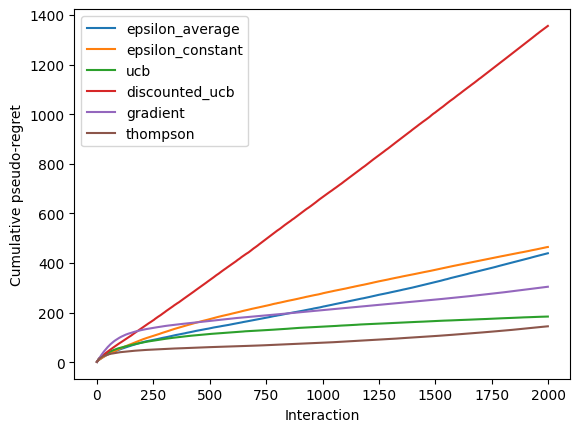

In [3]:
data=np.load(ROOT / "assets/source_data/lectures/bandits.npz")
for name in ["epsilon_average","epsilon_constant","ucb","discounted_ucb","gradient","thompson"]:
    regret=data[f"drifting_{name}_regret"]
    assert np.all(regret>=0)
    plt.plot(regret.cumsum(1).mean(0),label=name)
plt.xlabel("Interaction");plt.ylabel("Cumulative pseudo-regret");plt.legend();plt.show()

## A misspecified posterior is a measured limitation

In [4]:
for task in ["stationary","drifting"]:
    rewards=data[f"{task}_thompson_rewards"]
    print(task,"last500 mean",rewards[:,-500:].mean(),"independent instances",len(rewards))

stationary last500 mean 1.4369672732672973 independent instances 100
drifting last500 mean 1.4596621342075051 independent instances 100


Full fits: `decision-lab lectures --seed 0` (repeat seeds 1 and 2 where applicable). See [protocol](../docs/protocol.md), [results](../docs/results.md) and [references](../docs/references.md). These cells are numerical checks and evidence readers, not replacement training budgets.